# So sánh hiệu năng các mô hình trích xuất dữ liệu có cấu trúc

Notebook trực quan hóa kết quả benchmark trên **4 chiều đánh giá** của luận văn:

1. **Accuracy** — Field-level Exact Match & Token-level F1
2. **Robustness** — Sụt giảm Typed→Handwritten và EN→VN
3. **Efficiency** — Độ trễ (s/doc) & Chi phí (USD/1000 docs)
4. **Reliability** — Tỉ lệ ảo giác (hallucination) & Tuân thủ schema

So sánh đồng thời theo **mô hình** và **pipeline** (VLM Direct vs OCR-LLM).

Nguồn dữ liệu: các file `summary.jsonl` trong `results/`. Figure xuất ra `results/figures/`.

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Tái dùng logic chấm điểm reliability từ module evaluation
sys.path.append(str(Path.cwd().parent))
from evaluation.metrics import hallucination_flags, schema_compliant

RESULTS_DIR = Path("../results")
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Style chung cho mọi chart ----
mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "figure.autolayout": False,
})

# ---- Rút gọn tên model để chart dễ đọc ----
MODEL_SHORT = {
    "DeepSeek-V4-Flash": "DeepSeek-V4",
    "Llama-4-Maverick-17B-128E-Instruct-FP8": "Llama-4-Maverick",
    "Phi-4-multimodal-instruct": "Phi-4-MM",
    "gpt-4o": "GPT-4o",
    "gpt-5.2-chat": "GPT-5.2",
}
# Thứ tự model hiển thị cố định
MODEL_ORDER = ["GPT-5.2", "GPT-4o", "Llama-4-Maverick", "Phi-4-MM", "DeepSeek-V4"]

# Màu cố định cho từng model
MODEL_COLORS = {
    "GPT-5.2": "#1f77b4",
    "GPT-4o": "#2ca02c",
    "Llama-4-Maverick": "#ff7f0e",
    "Phi-4-MM": "#9467bd",
    "DeepSeek-V4": "#d62728",
}

# Nhãn pipeline tiếng Việt + style phân biệt (sắc độ / hatch)
PIPELINE_LABEL = {"ocr_llm": "OCR-LLM", "vlm_direct": "VLM Direct"}
PIPELINE_ORDER = ["vlm_direct", "ocr_llm"]
PIPELINE_HATCH = {"vlm_direct": "", "ocr_llm": "///"}

# Nhãn tiếng Việt cho loại tài liệu / ngôn ngữ / dạng văn bản
DOCTYPE_LABEL = {"contract": "Hợp đồng", "invoice": "Hóa đơn", "id_card": "CCCD"}
LANG_LABEL = {"EN": "Tiếng Anh", "VN": "Tiếng Việt"}
TEXTFORM_LABEL = {"typed": "Đánh máy", "handwritten": "Viết tay"}

def subtype_label(lang, textform, doctype):
    return f"{LANG_LABEL[lang]}\n{TEXTFORM_LABEL[textform]} · {DOCTYPE_LABEL[doctype]}"

# ---- BẢNG GIÁ (USD / 1 triệu token) — CHỈNH SỬA THEO GIÁ THỰC TẾ ----
# input = giá prompt token, output = giá completion token.
# Nguồn: Azure OpenAI / Azure AI Foundry / DeepSeek pricing (tổng hợp 2026-05).
# Llama-4-Maverick: Azure công bố khoảng $0.15–0.50 input -> lấy đại diện $0.35.
PRICING = {
    "gpt-5.2-chat":                              {"input": 1.75,  "output": 14.00},
    "gpt-4o":                                    {"input": 2.50,  "output": 10.00},
    "Llama-4-Maverick-17B-128E-Instruct-FP8":    {"input": 0.35,  "output": 0.60},
    "Phi-4-multimodal-instruct":                 {"input": 0.08,  "output": 0.32},
    "DeepSeek-V4-Flash":                         {"input": 0.14,  "output": 0.28},
}

# Field schema theo từng loại tài liệu (để chấm reliability)
FIELD_DIR = Path("../config/fields")
FIELDS_BY_DOCTYPE = {
    "contract": json.loads((FIELD_DIR / "contract.json").read_text(encoding="utf-8")).keys(),
    "invoice":  json.loads((FIELD_DIR / "invoice.json").read_text(encoding="utf-8")).keys(),
    "id_card":  json.loads((FIELD_DIR / "id_card.json").read_text(encoding="utf-8")).keys(),
}
FIELDS_BY_DOCTYPE = {k: list(v) for k, v in FIELDS_BY_DOCTYPE.items()}

def save_fig(fig, name):
    """Lưu figure ra PNG + PDF trong results/figures, cắt sát viền."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight")
    print(f"  saved -> {name}.png / .pdf")

print("Setup xong. FIG_DIR =", FIG_DIR.resolve())

Setup xong. FIG_DIR = D:\MasterDegree\LVTN\results\figures


## 1. Nạp & làm phẳng dữ liệu kết quả

Duyệt mọi `summary.jsonl`, parse tên thư mục run để lấy `lang / textform / doctype / pipeline / model`,
tạo:
- `df` — cấp document (mỗi dòng = 1 tài liệu) kèm điểm tổng, latency, token, cờ lỗi, hallucination, schema.
- `df_field` — dạng long, mỗi dòng = 1 field của 1 document, để vẽ per-field.

In [2]:
RUN_RE = re.compile(r"^(EN|VN)_(.+?)-([a-z_]+?)_(ocr_llm|vlm_direct)_(.+)_(\d{8}_\d{6})$")

def parse_run_name(name):
    """Tách 'VN_typed-id_card_ocr_llm_<model>_<ts>' -> (lang, textform, doctype, pipeline, model)."""
    m = RUN_RE.match(name)
    if not m:
        return None
    lang, textform, doctype, pipeline, model, _ts = m.groups()
    return lang, textform, doctype, pipeline, model

doc_rows = []
field_rows = []

for run_dir in sorted(RESULTS_DIR.glob("*/*/")):
    parsed = parse_run_name(run_dir.name)
    if parsed is None:
        continue
    lang, textform, doctype, pipeline, model = parsed
    summary = run_dir / "summary.jsonl"
    if not summary.exists():
        continue
    fields = FIELDS_BY_DOCTYPE.get(doctype, [])

    for line in summary.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        r = json.loads(line)
        pred = r.get("predicted") or {}
        gold = r.get("ground_truth") or {}
        err = r.get("error")
        usage = r.get("usage") or {}

        # Reliability: hallucination (chỉ tính field gold rỗng) + schema compliance
        hflags = hallucination_flags(pred, gold, fields)
        applicable = [v for v in hflags.values() if v is not None]
        hall_rate = (sum(applicable) / len(applicable)) if applicable else np.nan
        schema_ok = schema_compliant(pred, fields) and (err is None)

        doc_rows.append({
            "model_full": model,
            "model": MODEL_SHORT.get(model, model),
            "pipeline": pipeline,
            "pipeline_vi": PIPELINE_LABEL[pipeline],
            "lang": lang,
            "textform": textform,
            "doctype": doctype,
            "subtype": f"{lang}_{textform}-{doctype}",
            "doc_name": r.get("doc_name"),
            "overall_em": r.get("overall_exact_match"),
            "overall_f1": r.get("overall_token_f1"),
            "latency_sec": r.get("latency_sec"),
            "prompt_tokens": usage.get("prompt_tokens"),
            "completion_tokens": usage.get("completion_tokens"),
            "total_tokens": usage.get("total_tokens"),
            "has_error": err is not None,
            "hallucination": hall_rate,
            "schema_ok": schema_ok,
        })

        em = r.get("exact_match") or {}
        f1 = r.get("token_f1") or {}
        for fld in fields:
            field_rows.append({
                "model": MODEL_SHORT.get(model, model),
                "pipeline": pipeline,
                "doctype": doctype,
                "field": fld,
                "em": float(em.get(fld, False)),
                "f1": float(f1.get(fld, 0.0)),
            })

df = pd.DataFrame(doc_rows)
df_field = pd.DataFrame(field_rows)

# Cố định thứ tự hiển thị
df["model"] = pd.Categorical(df["model"], categories=MODEL_ORDER, ordered=True)
df["pipeline"] = pd.Categorical(df["pipeline"], categories=PIPELINE_ORDER, ordered=True)

# Chi phí: USD / 1000 docs từ token usage + PRICING
def cost_per_1000(row):
    p = PRICING.get(row["model_full"])
    if p is None or pd.isna(row["prompt_tokens"]):
        return np.nan
    pt = row["prompt_tokens"] or 0
    ct = row["completion_tokens"] or 0
    cost_per_doc = (pt * p["input"] + ct * p["output"]) / 1e6
    return cost_per_doc * 1000

df["cost_per_1000"] = df.apply(cost_per_1000, axis=1)

print(f"Số document: {len(df)}  |  số run: {df.groupby(['model','pipeline','subtype'], observed=True).ngroups}")
print(f"Model: {sorted(df['model'].dropna().unique().tolist())}")
print(f"Pipeline: {df['pipeline'].value_counts().to_dict()}")
print(f"Subtype: {df['subtype'].nunique()}  |  tài liệu lỗi: {int(df['has_error'].sum())}")
display(df.groupby(["model", "pipeline"], observed=True)[["overall_em", "overall_f1", "latency_sec"]].mean().round(3))

Số document: 540  |  số run: 45
Model: ['DeepSeek-V4', 'GPT-4o', 'GPT-5.2', 'Llama-4-Maverick', 'Phi-4-MM']
Pipeline: {'ocr_llm': 300, 'vlm_direct': 240}
Subtype: 5  |  tài liệu lỗi: 1


overall_em  overall_f1  latency_sec
model            pipeline                                       
GPT-5.2          vlm_direct       0.808       0.921        8.412
                 ocr_llm          0.721       0.882       11.087
GPT-4o           vlm_direct       0.824       0.899        3.952
                 ocr_llm          0.770       0.866        7.930
Llama-4-Maverick vlm_direct       0.836       0.923        1.761
                 ocr_llm          0.769       0.881        9.863
Phi-4-MM         vlm_direct       0.723       0.781       12.553
                 ocr_llm          0.702       0.829       11.802
DeepSeek-V4      ocr_llm          0.786       0.896       10.697

In [3]:
from matplotlib.patches import Patch

def pipeline_legend_handles(pipelines):
    return [Patch(facecolor="grey", hatch=PIPELINE_HATCH[p],
                  alpha=1.0 if p == "vlm_direct" else 0.55,
                  edgecolor="white", label=PIPELINE_LABEL[p]) for p in pipelines]

def grouped_bar(ax, data, value_col, ylabel, title, as_pct=False, annotate=True,
                fmt="{:.2f}", highlight=None, add_legend=True, legend_loc="upper right"):
    """Vẽ grouped bar: trục x = model, mỗi model có các cột theo pipeline.

    data: DataFrame đã groupby(model, pipeline) -> mean của value_col (reset_index).
    Màu theo model, hatch phân biệt pipeline.
    highlight: None | "max" | "min" -> tô viền đen đậm + ★ cho cột tốt nhất.
    """
    models = [m for m in MODEL_ORDER if m in data["model"].unique()]
    pipelines = [p for p in PIPELINE_ORDER if p in data["pipeline"].unique()]
    n_p = len(pipelines)
    width = 0.8 / n_p
    x = np.arange(len(models))

    all_bars = []  # (bar, value, annotation_obj)
    for j, pl in enumerate(pipelines):
        vals, colors = [], []
        for m in models:
            sub = data[(data["model"] == m) & (data["pipeline"] == pl)]
            v = sub[value_col].iloc[0] if len(sub) else np.nan
            vals.append(v)
            colors.append(MODEL_COLORS[m])
        offset = (j - (n_p - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width, color=colors,
                      edgecolor="white", linewidth=0.6,
                      hatch=PIPELINE_HATCH[pl],
                      alpha=1.0 if pl == "vlm_direct" else 0.55)
        for b, v in zip(bars, vals):
            ann = None
            if annotate and not np.isnan(v):
                # nhãn cột âm đặt xuống dưới để không đè vạch 0
                va = "bottom" if v >= 0 else "top"
                dy = 1.5 if v >= 0 else -1.5
                ann = ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v),
                                  ha="center", va=va, fontsize=8.5,
                                  xytext=(0, dy), textcoords="offset points")
            all_bars.append((b, v, ann))

    # Highlight cột tốt nhất
    if highlight in ("max", "min"):
        finite = [(b, v, a) for b, v, a in all_bars if v is not None and not np.isnan(v)]
        if finite:
            best = (max if highlight == "max" else min)(finite, key=lambda t: t[1])
            b, v, a = best
            b.set_edgecolor("black"); b.set_linewidth(3.0); b.set_zorder(6)
            star_va = "bottom" if v >= 0 else "top"
            star_dy = 11 if v >= 0 else -11
            ax.annotate("★", (b.get_x() + b.get_width() / 2, b.get_height()), ha="center",
                        va=star_va, color="#f1c40f", fontsize=15, fontweight="bold",
                        xytext=(0, star_dy), textcoords="offset points", zorder=8)
            if a is not None:
                a.set_fontweight("bold"); a.set_fontsize(10)

    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if as_pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    if add_legend:
        ax.legend(handles=pipeline_legend_handles(pipelines), title="Pipeline",
                  frameon=False, loc=legend_loc)
    return ax

print("Helper grouped_bar sẵn sàng.")

Helper grouped_bar sẵn sàng.


## 2. Chiều Accuracy — Độ chính xác

- **Exact Match (EM)**: tỉ lệ field khớp tuyệt đối sau chuẩn hóa.
- **Token-F1**: trùng khớp ở mức token (mềm hơn EM).
- **Heatmap per-field**: F1 trung bình theo từng trường, lộ ra trường khó (vd `governing_law`).

  saved -> fig_accuracy_em.png / .pdf


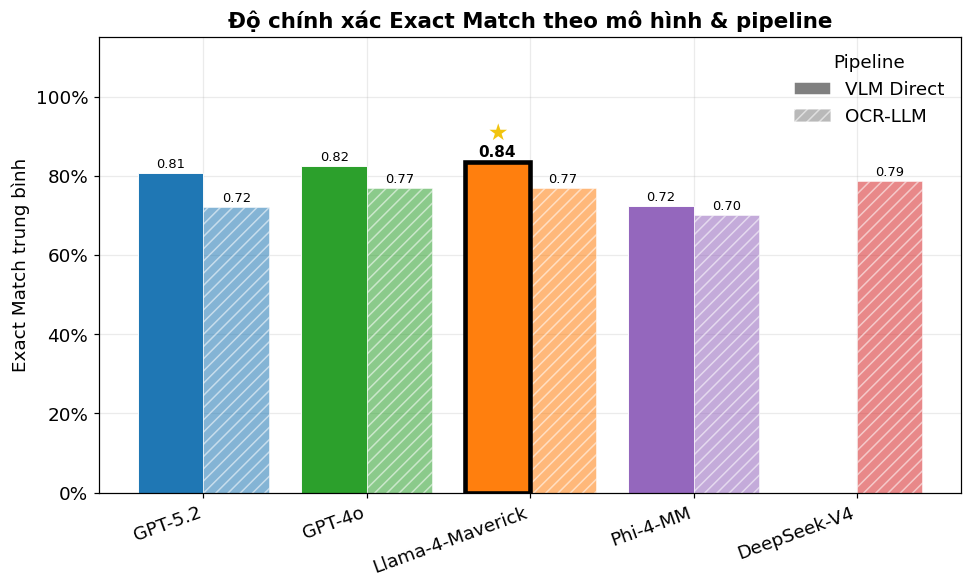

  saved -> fig_accuracy_f1.png / .pdf


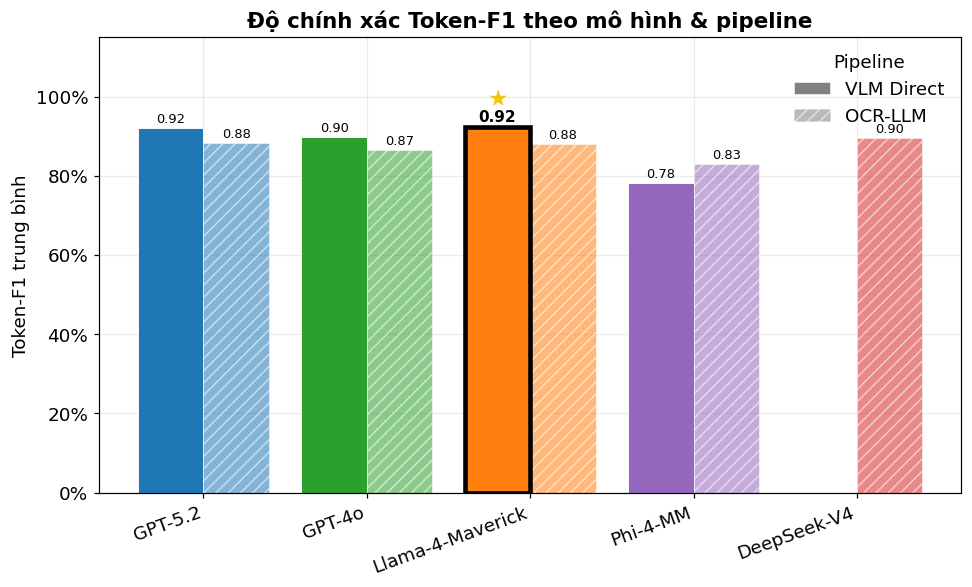

  saved -> fig_accuracy_per_field.png / .pdf


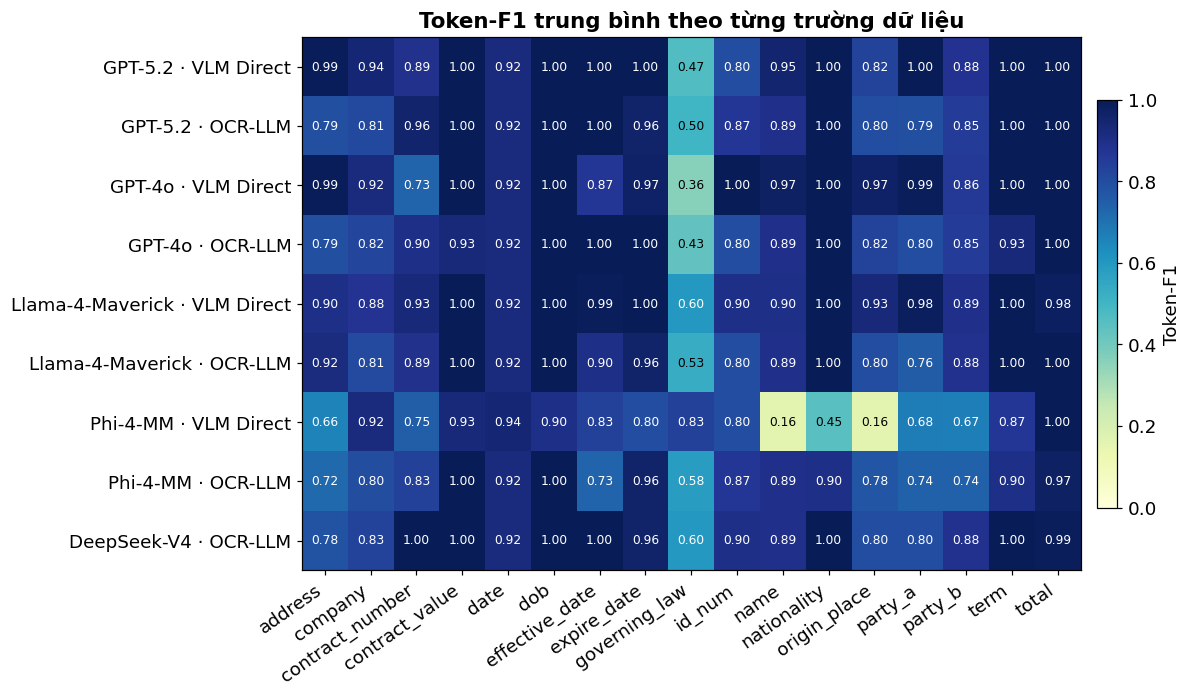

In [4]:
# --- EM & F1 trung bình theo model × pipeline ---
acc = (df.groupby(["model", "pipeline"], observed=True)[["overall_em", "overall_f1"]]
         .mean().reset_index())

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, acc, "overall_em", "Exact Match trung bình",
            "Độ chính xác Exact Match theo mô hình & pipeline",
            as_pct=True, highlight="max", legend_loc="upper right")
ax.set_ylim(0, 1.15)
fig.tight_layout(); save_fig(fig, "fig_accuracy_em"); plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, acc, "overall_f1", "Token-F1 trung bình",
            "Độ chính xác Token-F1 theo mô hình & pipeline",
            as_pct=True, highlight="max", legend_loc="upper right")
ax.set_ylim(0, 1.15)
fig.tight_layout(); save_fig(fig, "fig_accuracy_f1"); plt.show()

# --- Heatmap per-field (F1) : hàng = model · pipeline, cột = field ---
fld = df_field.copy()
fld["row"] = fld["model"].astype(str) + " · " + fld["pipeline"].map(PIPELINE_LABEL)
pivot = fld.pivot_table(index="row", columns="field", values="f1", aggfunc="mean")
# sắp hàng theo MODEL_ORDER × pipeline
row_order = [f"{m} · {PIPELINE_LABEL[p]}" for m in MODEL_ORDER for p in PIPELINE_ORDER]
pivot = pivot.reindex([r for r in row_order if r in pivot.index])

fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=35, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title("Token-F1 trung bình theo từng trường dữ liệu")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.55 else "black", fontsize=8)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Token-F1")
ax.grid(False)
fig.tight_layout(); save_fig(fig, "fig_accuracy_per_field"); plt.show()

**Nhận xét:** Kết quả thực nghiệm cho thấy ở phần lớn các mô hình, chiến lược trích xuất trực tiếp bằng mô hình thị giác – ngôn ngữ (Vision–Language Model - VLM Direct) đạt độ chính xác cao hơn quy trình nhận dạng ký tự kết hợp mô hình ngôn ngữ (OCR-LLM) trên cả hai thước đo Exact Match (EM) và Token-F1. Mô hình Llama-4-Maverick (VLM Direct) đạt kết quả cao nhất với EM bằng 83,6% và Token-F1 bằng 92,3%, kế đến là GPT-4o và GPT-5.2 ở cùng cấu hình; trong nhóm OCR-LLM, DeepSeek-V4 đạt EM cao nhất (78,6%), cho thấy một mô hình ngôn ngữ thuần văn bản vẫn có thể cạnh tranh khi được cung cấp văn bản OCR chất lượng tốt. Có thể nhận thấy rằng độ chênh lệch giữa EM và Token-F1 ở mọi mô hình là đáng kể, phản ánh hiện tượng kết quả đúng về mặt ngữ nghĩa nhưng khác biệt ở mức ký tự; bản đồ nhiệt theo từng trường chỉ ra `governing_law` là trường khó nhất do mô hình thường trả về cả cụm văn cảnh thay vì giá trị rút gọn, trong khi các trường có cấu trúc rõ ràng như `effective_date` hay `id_num` đạt điểm gần như tuyệt đối.

### Bảng so sánh độ chính xác theo ngôn ngữ

Hàng: **Pipeline → Mô hình**. Cột: **Ngôn ngữ → EM/F1**, kèm nhóm **Tổng hợp** cuối cùng.
Ô tô đậm theo cột = giá trị tốt nhất. Xuất ra `results/accuracy_table.csv`.

In [5]:
def accuracy_table(df):
    langs = ["EN", "VN"]
    metrics = [("overall_em", "EM"), ("overall_f1", "F1")]
    records = {}
    for pl in PIPELINE_ORDER:
        for m in MODEL_ORDER:
            sub = df[(df["pipeline"] == pl) & (df["model"] == m)]
            if sub.empty:
                continue
            row = {}
            for lang in langs:
                s = sub[sub["lang"] == lang]
                for col, mlabel in metrics:
                    row[(LANG_LABEL[lang], mlabel)] = s[col].mean() if len(s) else np.nan
            for col, mlabel in metrics:
                row[("Tổng hợp", mlabel)] = sub[col].mean()
            records[(PIPELINE_LABEL[pl], m)] = row
    tbl = pd.DataFrame.from_dict(records, orient="index")
    tbl.index = pd.MultiIndex.from_tuples(tbl.index, names=["Pipeline", "Mô hình"])
    tbl.columns = pd.MultiIndex.from_tuples(tbl.columns, names=["Ngôn ngữ", "Chỉ số"])
    col_order = [(LANG_LABEL["EN"], "EM"), (LANG_LABEL["EN"], "F1"),
                 (LANG_LABEL["VN"], "EM"), (LANG_LABEL["VN"], "F1"),
                 ("Tổng hợp", "EM"), ("Tổng hợp", "F1")]
    return tbl.reindex(columns=col_order)

acc_tbl = accuracy_table(df)
acc_tbl.to_csv(RESULTS_DIR / "accuracy_table.csv", encoding="utf-8-sig")
print("Đã lưu:", (RESULTS_DIR / "accuracy_table.csv").resolve())

display(acc_tbl.style
        .format("{:.1%}", na_rep="–")
        .background_gradient(cmap="Greens", axis=0)
        .highlight_max(axis=0, props="font-weight:bold; color:#b8860b;")
        .set_caption("Độ chính xác EM / Token-F1 theo ngôn ngữ (đậm = tốt nhất mỗi cột)"))

Đã lưu: D:\MasterDegree\LVTN\results\accuracy_table.csv


## 3. Chiều Robustness — Độ bền vững

- **Bản đồ nhiệt EM theo loại tài liệu**: mỗi hàng là một cặp mô hình · pipeline, mỗi cột là một nhóm
  tài liệu. Ô **xanh** = giữ vững độ chính xác, ô **đỏ** = sụt giảm. Vạch đen ngăn nhóm Tiếng Anh | Tiếng Việt.
- **Sụt giảm (drop)**: chênh lệch EM trung bình khi chuyển Đánh máy→Viết tay (hợp đồng VN)
  và Tiếng Anh→Tiếng Việt (hợp đồng đánh máy). Drop càng nhỏ càng bền vững (★ = bền nhất).

  saved -> fig_robustness_distribution.png / .pdf


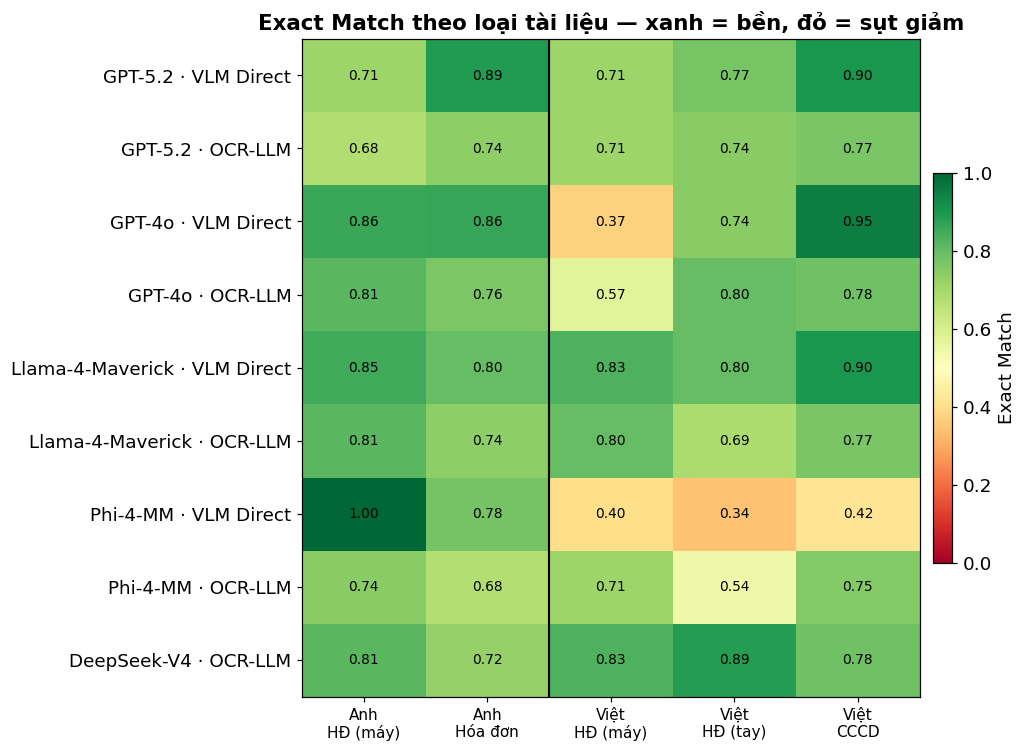

  saved -> fig_robustness_drop.png / .pdf


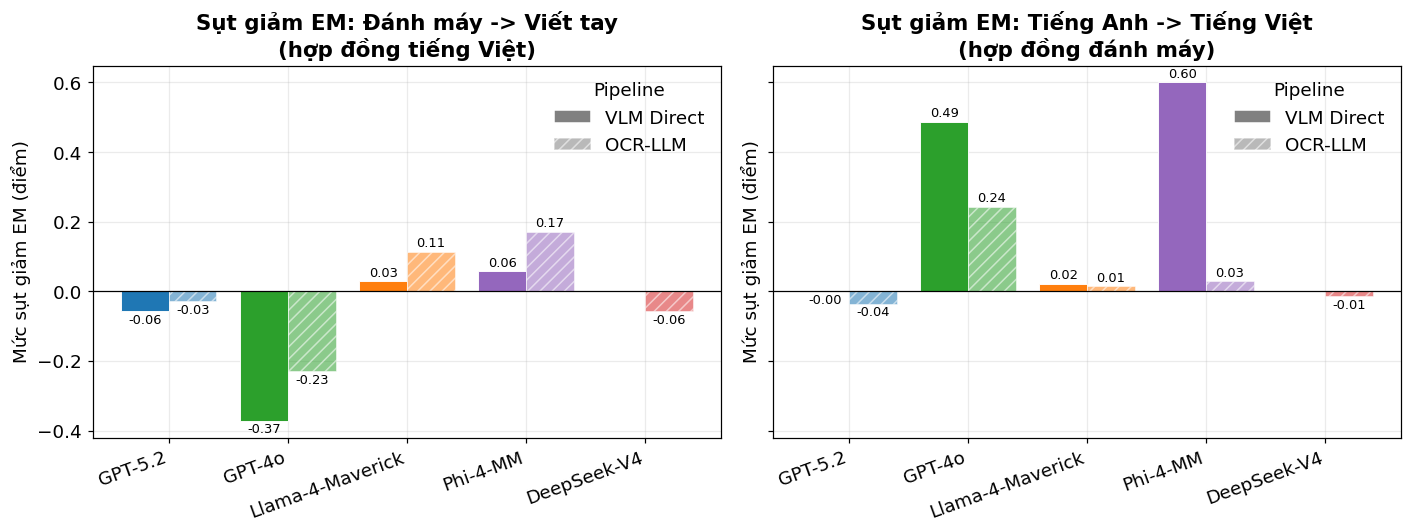

In [6]:
# --- Heatmap EM: hàng = model · pipeline, cột = loại tài liệu (dễ thấy chỗ sụt giảm) ---
subtypes = [("EN", "typed", "contract"), ("EN", "typed", "invoice"),
            ("VN", "typed", "contract"), ("VN", "handwritten", "contract"),
            ("VN", "typed", "id_card")]
sub_keys = [f"{l}_{t}-{d}" for l, t, d in subtypes]
NL = chr(10)
sub_labels = ["Anh" + NL + "HĐ (máy)", "Anh" + NL + "Hóa đơn",
              "Việt" + NL + "HĐ (máy)", "Việt" + NL + "HĐ (tay)", "Việt" + NL + "CCCD"]

rows, row_labels = [], []
for m in MODEL_ORDER:
    for pl in PIPELINE_ORDER:
        dm = df[(df["model"] == m) & (df["pipeline"] == pl)]
        if dm.empty:
            continue
        rows.append([dm[dm["subtype"] == sk]["overall_em"].mean() for sk in sub_keys])
        row_labels.append(f"{m} · {PIPELINE_LABEL[pl]}")
mat = np.array(rows, dtype=float)

fig, ax = plt.subplots(figsize=(9.5, 7))
im = ax.imshow(mat, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(sub_keys)))
ax.set_xticklabels(sub_labels, fontsize=10)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels)
ax.set_title("Exact Match theo loại tài liệu — xanh = bền, đỏ = sụt giảm")
# kẻ vạch ngăn EN | VN cho dễ đọc
ax.axvline(1.5, color="black", lw=1.4)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="black", fontweight="medium")
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("Exact Match")
ax.grid(False)
fig.tight_layout(); save_fig(fig, "fig_robustness_distribution"); plt.show()

# --- Drop bars: Đánh máy->Viết tay và EN->VN (trên hợp đồng) ---
drop_rows = []
for m in MODEL_ORDER:
    for pl in PIPELINE_ORDER:
        dm = df[(df["model"] == m) & (df["pipeline"] == pl)]
        if dm.empty:
            continue
        def me(sk):
            v = dm[dm["subtype"] == sk]["overall_em"]
            return v.mean() if len(v) else np.nan
        drop_rows.append({
            "model": m, "pipeline": pl,
            "drop_hw": me("VN_typed-contract") - me("VN_handwritten-contract"),
            "drop_vn": me("EN_typed-contract") - me("VN_typed-contract"),
        })
drop_df = pd.DataFrame(drop_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, col, title in zip(
        axes, ["drop_hw", "drop_vn"],
        ["Sụt giảm EM: Đánh máy -> Viết tay" + NL + "(hợp đồng tiếng Việt)",
         "Sụt giảm EM: Tiếng Anh -> Tiếng Việt" + NL + "(hợp đồng đánh máy)"]):
    g = drop_df.dropna(subset=[col])
    gb = g.groupby(["model", "pipeline"], observed=True)[col].mean().reset_index()
    grouped_bar(ax, gb.rename(columns={col: "v"}), "v",
                "Mức sụt giảm EM (điểm)", title, annotate=True, fmt="{:.2f}")
    ax.axhline(0, color="black", linewidth=0.8)
fig.tight_layout(); save_fig(fig, "fig_robustness_drop"); plt.show()

**Nhận xét:** Bản đồ nhiệt Exact Match theo loại tài liệu cho thấy sự phân hóa rõ rệt giữa các mô hình khi chuyển từ tiếng Anh sang tiếng Việt và từ văn bản đánh máy sang viết tay. Mô hình Phi-4-MM (VLM Direct) đạt EM tuyệt đối (1,00) trên hợp đồng tiếng Anh đánh máy nhưng sụt giảm mạnh xuống còn 0,39–0,42 trên các tài liệu tiếng Việt, tương ứng mức giảm khoảng 0,49 điểm EM giữa hai ngôn ngữ. Ngược lại, DeepSeek-V4 (OCR-LLM) thể hiện độ bền vững tốt nhất khi điểm EM trên tiếng Việt (82,0%) thậm chí cao hơn tiếng Anh (77,0%), cho thấy ưu thế của khâu OCR chuyên biệt đối với tài liệu tiếng Việt. Đối với chiều viết tay, đa số mô hình đều giảm độ chính xác, song quy trình OCR-LLM nhìn chung ổn định hơn VLM Direct trên hợp đồng viết tay tiếng Việt; điều này cho phép kết luận rằng tính bền vững không tỉ lệ thuận với độ chính xác trung bình, một mô hình có điểm tiếng Anh rất cao vẫn có thể kém tin cậy khi áp dụng cho dữ liệu thực tế đa ngôn ngữ.

## 4. Chiều Efficiency — Hiệu suất

- **Độ trễ**: thời gian xử lý trung bình mỗi tài liệu (giây) — gồm chart cột (kèm sai số) và chart
  thanh ngang xếp hạng để dễ so sánh.
- **Token sử dụng**: số token trung bình mỗi tài liệu (đại diện cho tải tính toán).
- **Chi phí**: USD trên 1000 tài liệu, ước tính từ token usage và bảng giá `PRICING` ở đầu notebook.

Cột/thanh viền vàng = giá trị **tốt nhất** (thấp nhất ở cả ba tiêu chí).

  saved -> fig_efficiency_latency.png / .pdf


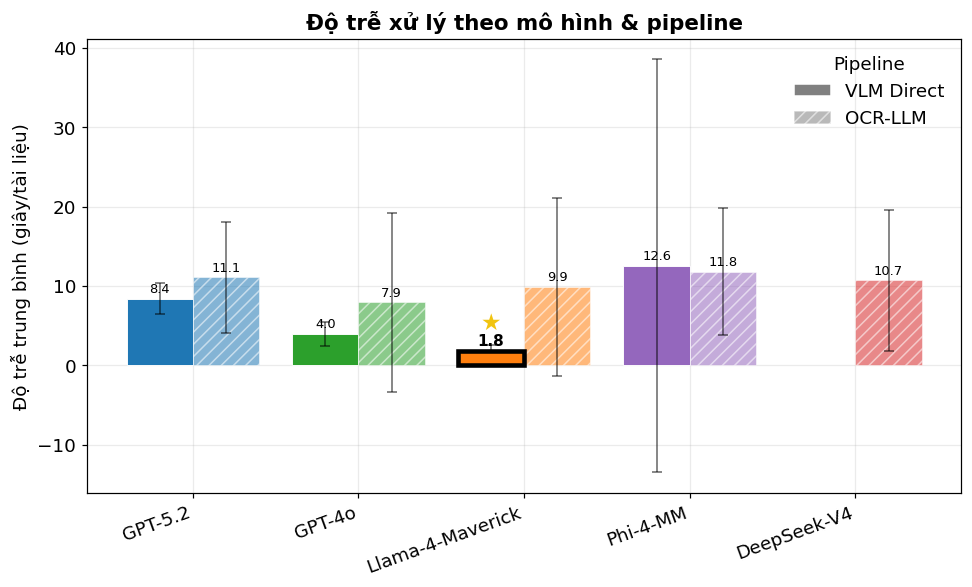

  saved -> fig_efficiency_latency_ranked.png / .pdf


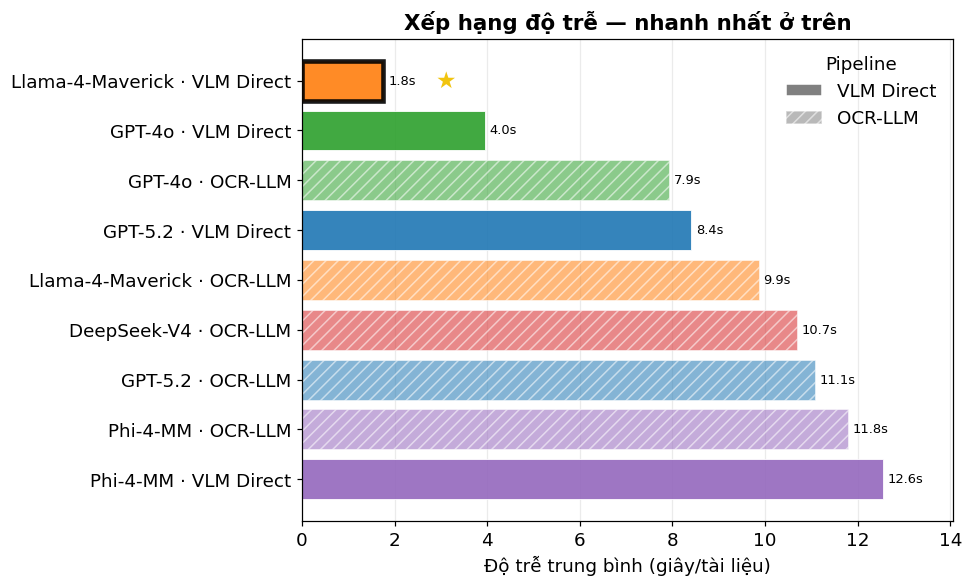

  saved -> fig_efficiency_tokens.png / .pdf


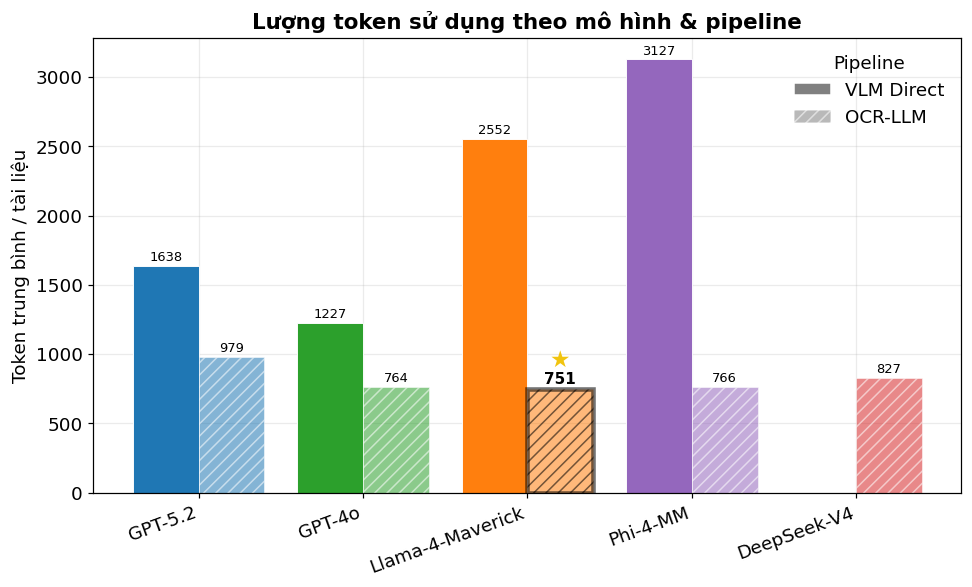

  saved -> fig_efficiency_cost.png / .pdf


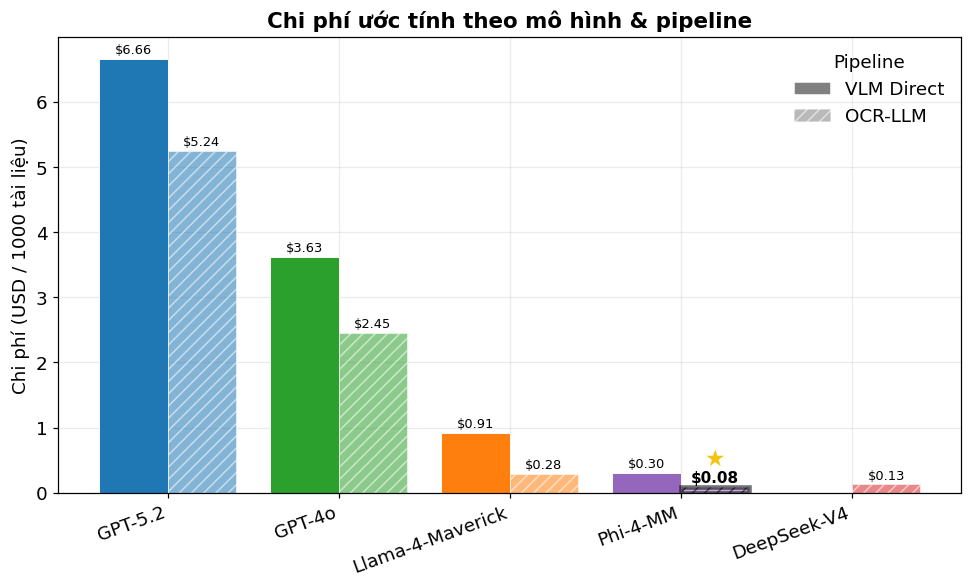

In [7]:
def grouped_bar_err(ax, data, mean_col, std_col, ylabel, title, fmt="{:.1f}",
                    highlight=None, legend_loc="upper right"):
    models = [m for m in MODEL_ORDER if m in data["model"].unique()]
    pipelines = [p for p in PIPELINE_ORDER if p in data["pipeline"].unique()]
    n_p = len(pipelines); width = 0.8 / n_p; x = np.arange(len(models))
    all_bars = []
    for j, pl in enumerate(pipelines):
        means, stds, colors = [], [], []
        for m in models:
            sub = data[(data["model"] == m) & (data["pipeline"] == pl)]
            means.append(sub[mean_col].iloc[0] if len(sub) else np.nan)
            stds.append(sub[std_col].iloc[0] if len(sub) else np.nan)
            colors.append(MODEL_COLORS[m])
        offset = (j - (n_p - 1) / 2) * width
        bars = ax.bar(x + offset, means, width, yerr=stds, capsize=3,
                      color=colors, edgecolor="white", linewidth=0.6,
                      hatch=PIPELINE_HATCH[pl],
                      alpha=1.0 if pl == "vlm_direct" else 0.55,
                      error_kw=dict(alpha=0.6, lw=1))
        for b, v in zip(bars, means):
            ann = None
            if not np.isnan(v):
                ann = ax.annotate(fmt.format(v), (b.get_x() + b.get_width()/2, v),
                                  ha="center", va="bottom", fontsize=8.5,
                                  xytext=(0, 2), textcoords="offset points")
            all_bars.append((b, v, ann))
    if highlight in ("max", "min"):
        finite = [(b, v, a) for b, v, a in all_bars if v is not None and not np.isnan(v)]
        if finite:
            b, v, a = (max if highlight == "max" else min)(finite, key=lambda t: t[1])
            b.set_edgecolor("black"); b.set_linewidth(3.0); b.set_zorder(6)
            ax.annotate("★", (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom", color="#f1c40f", fontsize=15, fontweight="bold", xytext=(0, 11), textcoords="offset points", zorder=8)
            if a is not None:
                a.set_fontweight("bold"); a.set_fontsize(10)
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(handles=pipeline_legend_handles(pipelines), title="Pipeline",
              frameon=False, loc=legend_loc)

def ranked_barh(ax, data, value_col, xlabel, title, fmt="{:.1f}", best="min"):
    """Thanh ngang xếp hạng theo value_col (mỗi thanh = 1 cặp model · pipeline)."""
    d = data.dropna(subset=[value_col]).copy()
    d = d.sort_values(value_col, ascending=(best == "min"))  # tốt nhất nằm trên cùng
    labels = [f"{r.model} · {PIPELINE_LABEL[r.pipeline]}" for r in d.itertuples()]
    colors = [MODEL_COLORS[m] for m in d["model"]]
    y = np.arange(len(d))[::-1]  # đảo để hạng 1 ở trên
    bars = ax.barh(y, d[value_col].values, color=colors, edgecolor="white",
                   linewidth=0.6, alpha=0.9)
    for bar_obj, pl in zip(bars, d["pipeline"]):
        bar_obj.set_hatch(PIPELINE_HATCH[pl])
        if pl == "ocr_llm":
            bar_obj.set_alpha(0.55)
    # highlight tốt nhất (thanh trên cùng)
    best_idx = 0
    bars[best_idx].set_edgecolor("black"); bars[best_idx].set_linewidth(3.0); bars[best_idx].set_zorder(6)
    ax.annotate("★", (bars[best_idx].get_width(), bars[best_idx].get_y() + bars[best_idx].get_height()/2), va="center", ha="left", color="#f1c40f", fontsize=15, fontweight="bold", xytext=(34, 0), textcoords="offset points")
    for bar_obj, v in zip(bars, d[value_col].values):
        ax.annotate(fmt.format(v), (v, bar_obj.get_y() + bar_obj.get_height()/2),
                    va="center", ha="left", fontsize=8.5,
                    xytext=(3, 0), textcoords="offset points")
    ax.set_yticks(y); ax.set_yticklabels(labels)
    ax.set_xlabel(xlabel); ax.set_title(title)
    ax.margins(x=0.12)
    ax.grid(axis="y", visible=False)

# ===== Độ trễ =====
lat = (df.groupby(["model", "pipeline"], observed=True)["latency_sec"]
         .agg(["mean", "std"]).reset_index())

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar_err(ax, lat, "mean", "std", "Độ trễ trung bình (giây/tài liệu)",
                "Độ trễ xử lý theo mô hình & pipeline", highlight="min")
fig.tight_layout(); save_fig(fig, "fig_efficiency_latency"); plt.show()

# Chart độ trễ dạng thanh ngang xếp hạng (dễ so sánh hơn)
fig, ax = plt.subplots(figsize=(9, 5.5))
ranked_barh(ax, lat.rename(columns={"mean": "latency_mean"}), "latency_mean",
            "Độ trễ trung bình (giây/tài liệu)",
            "Xếp hạng độ trễ — nhanh nhất ở trên",
            fmt="{:.1f}s", best="min")
ax.legend(handles=pipeline_legend_handles(PIPELINE_ORDER), title="Pipeline",
          frameon=False, loc="upper right")
fig.tight_layout(); save_fig(fig, "fig_efficiency_latency_ranked"); plt.show()

# ===== Số token sử dụng =====
tok = (df.groupby(["model", "pipeline"], observed=True)["total_tokens"]
         .mean().reset_index())
fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, tok, "total_tokens", "Token trung bình / tài liệu",
            "Lượng token sử dụng theo mô hình & pipeline",
            annotate=True, fmt="{:.0f}", highlight="min", legend_loc="upper right")
fig.tight_layout(); save_fig(fig, "fig_efficiency_tokens"); plt.show()

# ===== Chi phí (USD / 1000 docs) =====
cost = (df.dropna(subset=["cost_per_1000"])
          .groupby(["model", "pipeline"], observed=True)["cost_per_1000"]
          .mean().reset_index())
fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, cost, "cost_per_1000", "Chi phí (USD / 1000 tài liệu)",
            "Chi phí ước tính theo mô hình & pipeline",
            annotate=True, fmt="${:.2f}", highlight="min", legend_loc="upper right")
fig.tight_layout(); save_fig(fig, "fig_efficiency_cost"); plt.show()

**Nhận xét:** Về độ trễ, Llama-4-Maverick (VLM Direct) xử lý nhanh nhất với 1,76 giây mỗi tài liệu, trong khi Phi-4-MM (VLM Direct) chậm nhất với 12,55 giây. Về lượng token tiêu thụ, cấu hình OCR-LLM của Llama-4-Maverick tiết kiệm nhất (khoảng 751 token mỗi tài liệu), còn Phi-4-MM (VLM Direct) tiêu tốn nhiều nhất (khoảng 3.127 token). Về chi phí ước tính, các mô hình nhỏ có lợi thế rõ rệt: Phi-4-MM (OCR-LLM) chỉ tốn khoảng 0,08 USD cho 1.000 tài liệu, trong khi GPT-5.2 (VLM Direct) tốn tới 6,66 USD do đơn giá token cao. Có thể nhận thấy rằng chiến lược VLM Direct rút ngắn độ trễ đối với các mô hình thị giác mạnh nhờ loại bỏ bước OCR trung gian, nhưng không bảo đảm chi phí thấp hơn, vì chi phí phụ thuộc chủ yếu vào đơn giá token của từng nhà cung cấp.

## 5. Chiều Reliability — Độ tin cậy

- **Tỉ lệ bịa thông tin (hallucination)**: trong các trường mà ground-truth rỗng (không có gì để trích),
  mô hình vẫn tự sinh ra giá trị. Càng **thấp** càng tốt.
- **Tỉ lệ tuân thủ schema**: tỉ lệ tài liệu trả về đúng schema phẳng (đủ key, value scalar, không lỗi).
  Càng **cao** càng tốt.

  saved -> fig_reliability.png / .pdf


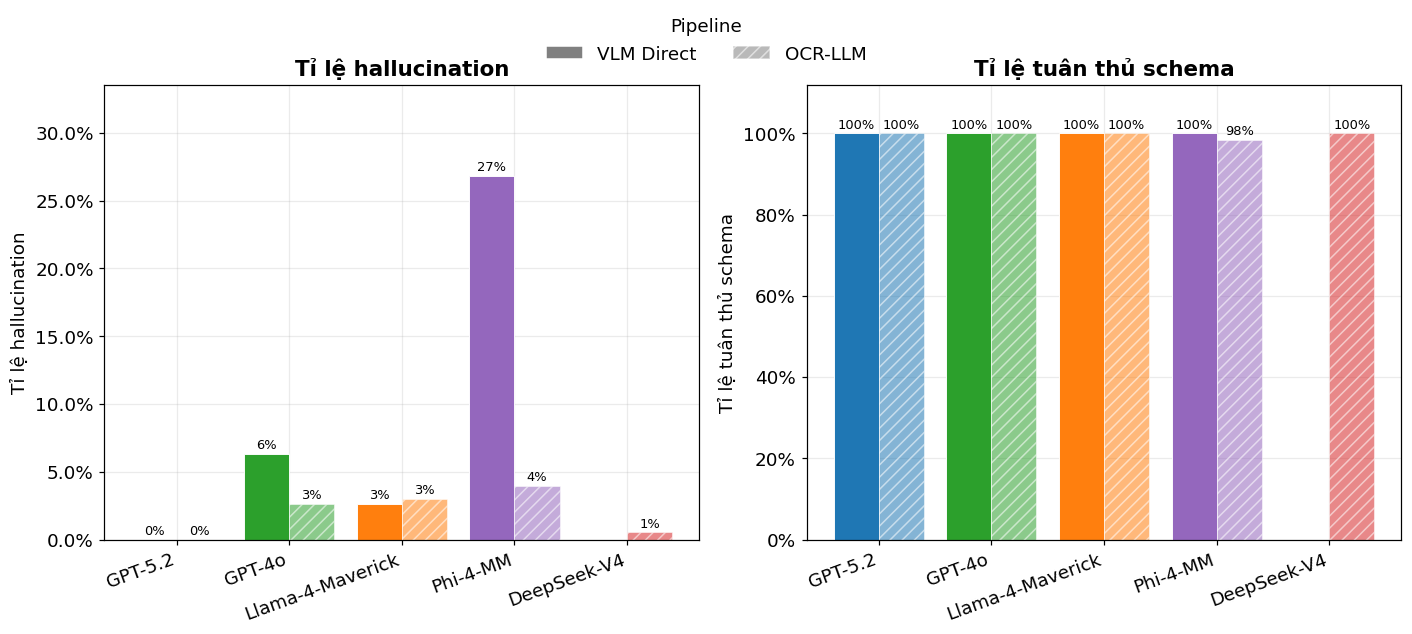

In [8]:
rel = (df.groupby(["model", "pipeline"], observed=True)
         .agg(hallucination=("hallucination", "mean"),
              schema_ok=("schema_ok", "mean"))
         .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
grouped_bar(axes[0], rel, "hallucination", "Tỉ lệ hallucination",
            "Tỉ lệ hallucination", as_pct=True, fmt="{:.0%}", add_legend=False)
axes[0].set_ylim(0, max(0.05, rel["hallucination"].max() * 1.25))
grouped_bar(axes[1], rel, "schema_ok", "Tỉ lệ tuân thủ schema",
            "Tỉ lệ tuân thủ schema", as_pct=True, fmt="{:.0%}", add_legend=False)
axes[1].set_ylim(0, 1.12)

# Một legend chung cho cả hai subplot
fig.legend(handles=pipeline_legend_handles(PIPELINE_ORDER), title="Pipeline",
           frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=2)
fig.tight_layout(); save_fig(fig, "fig_reliability"); plt.show()

**Nhận xét:** Trên thước đo tỉ lệ tuân thủ schema, hầu hết các cấu hình đều đạt xấp xỉ 100%, chứng tỏ các mô hình tuân thủ tốt định dạng JSON phẳng được yêu cầu. Tuy nhiên, tỉ lệ hallucination — hiện tượng mô hình tự sinh giá trị cho những trường vốn rỗng trong nhãn chuẩn — phân hóa mạnh giữa các mô hình: GPT-5.2 đạt mức 0% ở cả hai pipeline, thể hiện tính kỷ luật cao nhất, trong khi Phi-4-MM (VLM Direct) lên tới 26,8%, cho thấy xu hướng sinh khống thông tin nghiêm trọng khi xử lý trực tiếp trên ảnh. Kết quả này cho thấy độ tin cậy là tiêu chí cần xét song song với độ chính xác, bởi một mô hình có thể đạt EM khá nhưng vẫn rủi ro cao khi triển khai thực tế nếu thường xuyên bịa giá trị cho các trường không tồn tại.

## 6. Bảng tổng hợp (leaderboard)

Tổng hợp cả 4 chiều cho từng cặp (mô hình, pipeline). Xuất ra `results/summary_table.csv`
để dùng trực tiếp trong luận văn.

In [9]:
board = (df.groupby(["model", "pipeline"], observed=True)
           .agg(n_docs=("doc_name", "count"),
                exact_match=("overall_em", "mean"),
                token_f1=("overall_f1", "mean"),
                latency_sec=("latency_sec", "mean"),
                cost_per_1000_usd=("cost_per_1000", "mean"),
                hallucination=("hallucination", "mean"),
                schema_compliance=("schema_ok", "mean"))
           .reset_index())
board["pipeline"] = board["pipeline"].map(PIPELINE_LABEL)
board = board.sort_values(["exact_match"], ascending=False).reset_index(drop=True)

num_cols = ["exact_match", "token_f1", "latency_sec", "cost_per_1000_usd",
            "hallucination", "schema_compliance"]
board[num_cols] = board[num_cols].round({
    "exact_match": 3, "token_f1": 3, "latency_sec": 2,
    "cost_per_1000_usd": 2, "hallucination": 3, "schema_compliance": 3})

out_csv = RESULTS_DIR / "summary_table.csv"
board.to_csv(out_csv, index=False, encoding="utf-8-sig")
print(f"Đã lưu: {out_csv.resolve()}")

styled = board.style.background_gradient(subset=["exact_match", "token_f1", "schema_compliance"],
                                         cmap="Greens") \
                    .background_gradient(subset=["latency_sec", "cost_per_1000_usd", "hallucination"],
                                         cmap="Reds") \
                    .format({"exact_match": "{:.1%}", "token_f1": "{:.1%}",
                             "schema_compliance": "{:.1%}", "hallucination": "{:.1%}",
                             "latency_sec": "{:.2f}s", "cost_per_1000_usd": "${:.2f}"})
display(styled)

Đã lưu: D:\MasterDegree\LVTN\results\summary_table.csv


,model,pipeline,n_docs,exact_match,token_f1,latency_sec,cost_per_1000_usd,hallucination,schema_compliance
0,Llama-4-Maverick,VLM Direct,60,83.6%,92.3%,1.76s,$0.91,2.6%,100.0%
1,GPT-4o,VLM Direct,60,82.4%,89.9%,3.95s,$3.63,6.3%,100.0%
2,GPT-5.2,VLM Direct,60,80.8%,92.1%,8.41s,$6.66,0.0%,100.0%
3,DeepSeek-V4,OCR-LLM,60,78.6%,89.6%,10.70s,$0.13,0.5%,100.0%
4,GPT-4o,OCR-LLM,60,77.0%,86.6%,7.93s,$2.45,2.6%,100.0%
5,Llama-4-Maverick,OCR-LLM,60,76.9%,88.1%,9.86s,$0.28,3.0%,100.0%
6,Phi-4-MM,VLM Direct,60,72.3%,78.1%,12.55s,$0.30,26.8%,100.0%
7,GPT-5.2,OCR-LLM,60,72.1%,88.2%,11.09s,$5.24,0.0%,100.0%
8,Phi-4-MM,OCR-LLM,60,70.2%,82.9%,11.80s,$0.08,3.9%,98.3%


**Nhận xét:** Tổng hợp cả bốn chiều đánh giá, Llama-4-Maverick (VLM Direct) là cấu hình cân bằng tốt nhất khi đồng thời dẫn đầu về độ chính xác, độ trễ thấp, chi phí hợp lý và tỉ lệ hallucination thấp. Đối với tài liệu tiếng Việt, quy trình OCR-LLM kết hợp DeepSeek-V4 là lựa chọn đáng cân nhắc nhờ độ bền vững vượt trội. Kết quả này cho phép trả lời mục tiêu so sánh của đề tài: chiến lược VLM Direct phù hợp với tài liệu tiếng Anh đánh máy và yêu cầu độ trễ thấp, còn OCR-LLM giữ vai trò quan trọng đối với tài liệu tiếng Việt, viết tay, hoặc khi sử dụng các mô hình ngôn ngữ thuần văn bản.